### Notebook de la clase: de datos a una pregunta
*21.09.2026*

In [4]:
## IMPORTAR BIBLIOTECAS PARA USARLAS

import numpy as np #permite trabajar con matrices, arreglos, etc.
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
type(pd) #preguntas qué tipo de variable es

module

### ARCHIVO ONI ###

In [7]:
filename = "../data/oni_mensual_1981_2026.csv" #asignamos el nombre a una variable
type(filename) ; #str = cadena de caracteres

str

In [9]:
oni = pd.read_csv(filename, parse_dates=["time"]) 
#funcion de pandas para leer la variable ; parse_date = usar una de las columnas y leerla como fechas

In [10]:
oni

,time,oni_degC
0,1981-09-01,-0.25
1,1981-10-01,-0.16
2,1981-11-01,-0.13
3,1981-12-01,-0.15
4,1982-01-01,-0.08
...,...,...
535,2026-04-01,0.11
536,2026-05-01,0.46
537,2026-06-01,0.95
538,2026-07-01,1.39


In [11]:
type(oni)

pandas.DataFrame

In [12]:
oni.columns

Index(['time', 'oni_degC'], dtype='str')

In [13]:
oni.shape #me dice cuantas filas y columnas tiene

(540, 2)

In [16]:
oni.describe() #te da una estadística muy simple de los datos

,time,oni_degC
count,540,540.000000
mean,2004-02-15 08:00:00,0.046185
min,1981-09-01 00:00:00,-1.850000
25%,1992-11-23 12:00:00,-0.552500
50%,2004-02-15 12:00:00,-0.075000
75%,2015-05-08 18:00:00,0.572500
max,2026-08-01 00:00:00,2.750000
std,NaN,0.871231


In [32]:
# ¿Cuántos meses tiene el archivo?
tiempo = oni.time
tiempo

len(oni)

oni['time']

0     1981-09-01
1     1981-10-01
2     1981-11-01
3     1981-12-01
4     1982-01-01
         ...    
535   2026-04-01
536   2026-05-01
537   2026-06-01
538   2026-07-01
539   2026-08-01
Name: time, Length: 540, dtype: datetime64[us]

In [36]:
# ¿Cuál es el calor máximo y mínimo de oni_DegC?
degC = oni.oni_degC
degC
degC.describe()

oni['oni_degC'].min()
oni['oni_degC'].max()

np.float64(-1.85)

In [40]:
# ¿Qué fecha corresponde al valor máximo?
imax = oni.oni_degC.idxmax()  #dentro del oni, ve y busca este índice
imax
oni.loc[imax]

time        2016-01-01 00:00:00
oni_degC                   2.75
Name: 412, dtype: object

In [41]:
type(tiempo)

pandas.Series

In [42]:
type(degC)

pandas.Series

In [43]:
oni.iloc[1] #te ayuda a buscar por filas

time        1981-10-01 00:00:00
oni_degC                  -0.16
Name: 1, dtype: object

In [45]:
oni.oni_degC > 0.5 
#te ayuda con los condicionales; en este caso son buscarlos días en que son niños, con esto podemos crear una mascara

0      False
1      False
2      False
3      False
4      False
       ...  
535    False
536    False
537     True
538     True
539     True
Name: oni_degC, Length: 540, dtype: bool

In [48]:
oni.loc[oni.oni_degC > 0.5]
# buscamos en oni todas las filas donde se cumpla que el indice oni es mayor a 0.5

,time,oni_degC
9,1982-06-01,0.66
10,1982-07-01,0.72
11,1982-08-01,0.79
12,1982-09-01,1.07
13,1982-10-01,1.58
...,...,...
511,2024-04-01,1.26
512,2024-05-01,0.82
537,2026-06-01,0.95
538,2026-07-01,1.39


In [52]:
niño = oni.loc[oni.oni_degC > 0.5]
# guardamos en una variable

In [59]:
niña = oni.loc[oni.oni_degC < -0.5]

In [60]:
niña

,time,oni_degC
26,1983-11-01,-0.81
27,1983-12-01,-1.00
28,1984-01-01,-0.91
29,1984-02-01,-0.60
33,1984-06-01,-0.51
...,...,...
496,2023-01-01,-0.71
497,2023-02-01,-0.54
530,2025-11-01,-0.57
531,2025-12-01,-0.61


In [56]:
# operadores : >   <   >=  <=   == (igual)  != (diferente a)

In [57]:
# condicionales : if, else, elif (if else)

In [61]:
# EJEMPLO DE CONDICIONAL
x = 1.2

if x >= 0.5:
    print("niño")
elif x <= -0.5:
    print("niña")
else:
    print("neutral")

niño


In [76]:
# CREAR UNA FUNCIÓN CONDICIONAL PARA SABER SI ES NIÑO/NIÑA

def enso_phase(oni_value):
    '''Esta funcion me dice la fase del ENSO dependiendo del valor de ONI
    INPUT: oni_value: float
    Output: phase: str '''
    if oni_value >= 0.5:
        return("El niño")
    elif oni_value <= -0.5:
        return("La niña")
    else:
        return("neutral")

In [70]:
enso_phase(0.8)

'El niño'

In [77]:
? enso_phase

Signature:  enso_phase(oni_value)
Docstring:
Esta funcion me dice la fase del ENSO dependiendo del valor de ONI
INPUT: oni_value: float
Output: phase: str 
File:      c:\users\angel\appdata\local\temp\ipykernel_23960\4139129149.py
Type:      function

In [ ]:
# ciclos : if

In [79]:
values = [1.2, -0.7, 0.0] #definimos una lista

for value in values:
    print(value, enso_phase(value))

1.2 El niño
-0.7 La niña
0.0 neutral


In [81]:
for value in degC:
    print(value, enso_phase(value))

-0.25 neutral
-0.16 neutral
-0.13 neutral
-0.15 neutral
-0.08 neutral
-0.05 neutral
0.07 neutral
0.19 neutral
0.47 neutral
0.66 El niño
0.72 El niño
0.79 El niño
1.07 El niño
1.58 El niño
1.97 El niño
2.18 El niño
2.23 El niño
2.18 El niño
1.92 El niño
1.54 El niño
1.29 El niño
1.06 El niño
0.72 El niño
0.31 neutral
-0.08 neutral
-0.46 neutral
-0.81 La niña
-1.0 La niña
-0.91 La niña
-0.6 La niña
-0.42 neutral
-0.34 neutral
-0.43 neutral
-0.51 La niña
-0.45 neutral
-0.3 neutral
-0.16 neutral
-0.24 neutral
-0.56 La niña
-0.92 La niña
-1.14 La niña
-1.04 La niña
-0.85 La niña
-0.77 La niña
-0.78 La niña
-0.78 La niña
-0.63 La niña
-0.49 neutral
-0.46 neutral
-0.4 neutral
-0.35 neutral
-0.27 neutral
-0.36 neutral
-0.49 neutral
-0.47 neutral
-0.31 neutral
-0.2 neutral
-0.12 neutral
-0.04 neutral
0.22 neutral
0.44 neutral
0.71 El niño
0.94 El niño
1.14 El niño
1.22 El niño
1.23 El niño
1.19 El niño
1.06 El niño
0.95 El niño
0.97 El niño
1.22 El niño
1.51 El niño
1.7 El niño
1.65 El niño
1.4

In [84]:
#o también se podría hacer como:

oni["phase"] = oni.oni_degC.apply(enso_phase) #hacemos una nueva columna y le asignamos un valor
# apply nos ayuda a aplicar la funcion en una columna

oni.head

<bound method NDFrame.head of           time  oni_degC    phase
0   1981-09-01     -0.25  neutral
1   1981-10-01     -0.16  neutral
2   1981-11-01     -0.13  neutral
3   1981-12-01     -0.15  neutral
4   1982-01-01     -0.08  neutral
..         ...       ...      ...
535 2026-04-01      0.11  neutral
536 2026-05-01      0.46  neutral
537 2026-06-01      0.95  El niño
538 2026-07-01      1.39  El niño
539 2026-08-01      1.80  El niño

[540 rows x 3 columns]>

### ARCHIVO DE PRECIPITACIÓN ###

In [104]:
filenamee = "../data/precipitacion_ensenada_1981_2026.csv"
type(filename)

str

In [105]:
prep = pd.read_csv(filenamee, parse_dates=["time"]) 

In [89]:
prep

,time,precip_mm
0,1981-09-01,2.0
1,1981-10-01,5.0
2,1981-11-01,68.5
3,1981-12-01,20.0
4,1982-01-01,54.8
...,...,...
535,2026-04-01,15.0
536,2026-05-01,17.0
537,2026-06-01,0.0
538,2026-07-01,0.0


In [90]:
prep.info()

<class 'pandas.DataFrame'>
RangeIndex: 540 entries, 0 to 539
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   time       540 non-null    datetime64[us]
 1   precip_mm  511 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 8.6 KB


In [100]:
prep.describe() #te da una estadística muy simple de los datos

,time,precip_mm
count,540,511.000000
mean,2004-02-15 08:00:00,23.015264
min,1981-09-01 00:00:00,0.000000
25%,1992-11-23 12:00:00,0.200000
50%,2004-02-15 12:00:00,7.000000
75%,2015-05-08 18:00:00,30.850000
max,2026-08-01 00:00:00,237.600000
std,NaN,35.298179


In [91]:
prep.isna().sum() #para saber cuántos NaN tengo en mi archivo

time          0
precip_mm    29
dtype: int64

### HACEMOS LAS GRÁFICAS ###

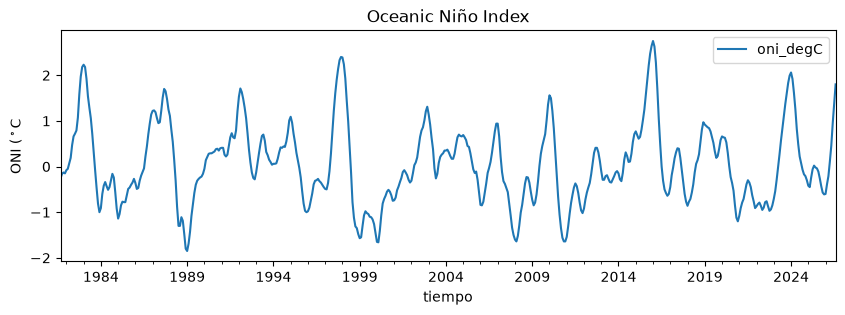

In [96]:
oni.plot(x="time", y="oni_degC", figsize = (10,3))
plt.ylabel(r"ONI ($^\circ$C")
plt.xlabel("tiempo")
plt.title("Oceanic Niño Index")
plt.show()

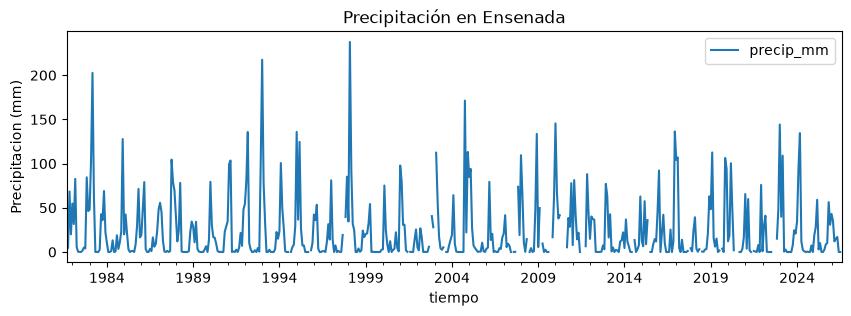

In [108]:
prep.plot(x="time", y="precip_mm", figsize = (10,3))
plt.ylabel(r"Precipitacion (mm)")
plt.xlabel("tiempo")
plt.title("Precipitación en Ensenada")
plt.show()

### TAREA 1 ###
*encuentra los meses para los que no tenemos datos de precipitacion*

In [ ]:
prep.isna().sum() #para saber cuántos NaN tengo en mi archivo
prep.iloc[prep[""]]